# CIE 2 – Machine Learning
## Activity 2: Simple House Price Prediction
**Unit II – Supervised Learning: Regression**

- **Algorithm**: Linear Regression
- **Objective**: Predict a continuous house-value target using Linear Regression, test the model and evaluate its performance using one input feature (`MedInc`).

### 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 3. Load Dataset

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
print("Dataset loaded successfully.")

Dataset loaded successfully.


### 4. Inspect Dataset

In [3]:
display(df.head())
display(df.tail())
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:", df.columns.tolist())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


Rows: 20640
Columns: 9

Column names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [4]:
df.info()
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


### 5. Check Missing Values and Duplicates

In [5]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())

Missing values in each column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total missing values: 0
Exact duplicate rows: 0


In [6]:
df_clean = df.copy().dropna()
print("Shape after checking missing values:", df_clean.shape)

Shape after checking missing values: (20640, 9)


### 6. Select Input Feature and Target

In [7]:
X = df_clean[["MedInc"]]
y = df_clean["MedHouseVal"]
print("Input feature:", X.columns.tolist())
print("Target:", y.name)

Input feature: ['MedInc']
Target: MedHouseVal


### 7. Visualize the Relationship

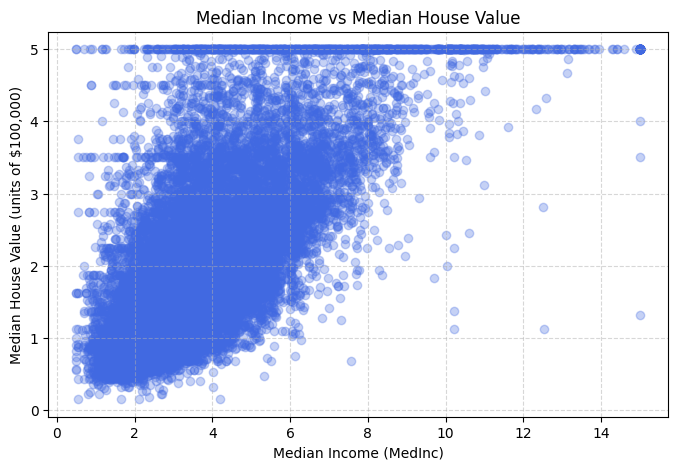

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(X["MedInc"], y, alpha=0.3, color='royalblue')
plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income (MedInc)")
plt.ylabel("Median House Value (units of $100,000)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 8. Train-Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 16512
Testing records: 4128


### 9. Train Linear Regression

In [10]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model trained successfully.")

coefficient = model.coef_[0]
intercept = model.intercept_
print("Coefficient (slope):", coefficient)
print("Intercept:", intercept)
print(f"\nEquation: Predicted MedHouseVal = {intercept:.4f} + {coefficient:.4f} * MedInc")

Model trained successfully.
Coefficient (slope): 0.4193384939381271
Intercept: 0.4445972916907879

Equation: Predicted MedHouseVal = 0.4446 + 0.4193 * MedInc


### 10. Generate Test Predictions

In [11]:
y_pred = model.predict(X_test)
comparison = pd.DataFrame({"Actual House Value": y_test.values, "Predicted House Value": y_pred})
display(comparison.head(10))

,Actual House Value,Predicted House Value
0,0.47700,1.149589
1,0.45800,1.506069
2,5.00001,1.903937
3,2.18600,2.850594
4,2.78000,2.006633
5,1.58700,2.421652
6,1.98200,2.576472
7,1.57500,1.992292
8,3.40000,2.458932
9,4.46600,3.846774


### 11. Evaluate the Model

In [12]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R-squared (R2): {r2:.4f}")

MAE: 0.6299
MSE: 0.7091
RMSE: 0.8421
R-squared (R2): 0.4589


### 12. Actual vs Predicted Plot

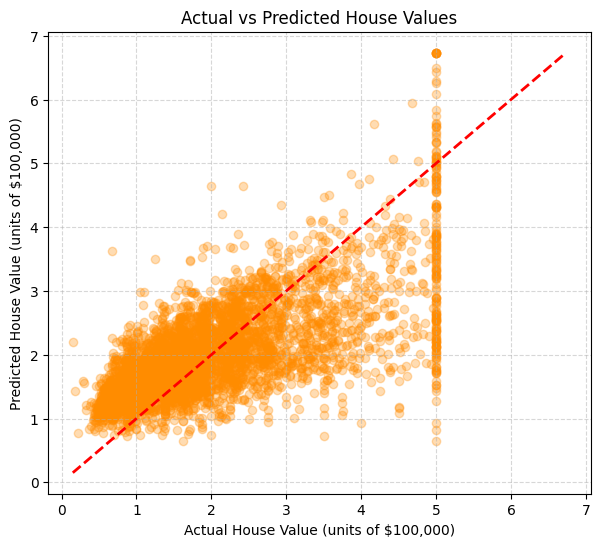

In [13]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='darkorange')
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--", color='red', linewidth=2)
plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual House Value (units of $100,000)")
plt.ylabel("Predicted House Value (units of $100,000)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 13. Predict a New Example

In [14]:
new_income = X_train["MedInc"].median()
new_data = pd.DataFrame({"MedInc": [new_income]})
new_prediction = model.predict(new_data)[0]

print("New median income:", new_income)
print(f"Predicted house value (units of $100,000): {new_prediction:.4f}")
print(f"Approximate value in dollars: ${new_prediction * 100000:,.2f}")

New median income: 3.5458
Predicted house value (units of $100,000): 1.9315
Approximate value in dollars: $193,148.77
